# Analisis dan Visualisasi Clustering Gempa Bumi Menggunakan K-Means

**Nama:** Lizza Putri Sugiarto  
**Dataset:** Global Earthquakes Seismic Telemetry  
**Sumber:** [Kaggle – Global Earthquakes Seismic Telemetry](https://www.kaggle.com/datasets/luthfimuthathohirin/global-earthquakes-seismic-telemetry)

## Tujuan praktikum
1. Memahami struktur dan kualitas dataset.
2. Melakukan eksplorasi data (EDA).
3. Melakukan preprocessing dan standarisasi fitur.
4. Menentukan jumlah cluster dengan Elbow Method dan Silhouette Score.
5. Menerapkan K-Means dan mengevaluasi hasilnya.
6. Menginterpretasikan karakteristik cluster berdasarkan statistik dan visualisasi.

**Fitur utama:** `latitude`, `longitude`, `depth`, dan `mag`.

**Catatan metodologis:** K-Means menggunakan jarak Euclidean. Latitude dan longitude merupakan koordinat geografis, sehingga jarak Euclidean pada derajat koordinat bukan jarak geodesik yang sesungguhnya. Hasil ini merupakan pengelompokan eksploratif, bukan penetapan zona tektonik atau tingkat bahaya gempa. Nilai ekstrem tidak otomatis dihapus karena dapat merepresentasikan kejadian yang valid.


## 0. Persiapan library dan konfigurasi

Gunakan `%pip` agar instalasi diarahkan ke environment kernel Jupyter.

In [1]:
# Jalankan jika library belum tersedia:
%pip install -q pandas numpy matplotlib seaborn scikit-learn

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.decomposition import PCA

RANDOM_STATE = 42
FEATURES = ["latitude", "longitude", "depth", "mag"]
K_VALUES = list(range(2, 9))
SILHOUETTE_SAMPLE_SIZE = 3000
SELECTED_K = 4  # Tinjau evaluasi sebelum menetapkan K akhir.

OUTPUT_DIR = Path("output_clustering_revisi")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")

print("Library berhasil diimpor.")
print("Folder output:", OUTPUT_DIR.resolve())


Note: you may need to restart the kernel to use updated packages.


Library berhasil diimpor.
Folder output: /mnt/data/output_clustering_revisi


## 1. Memuat dataset

Letakkan CSV di folder yang sama dengan notebook. Jika menggunakan alamat Windows, gunakan raw string seperti `r"C:\\folder\\file.csv"`.

In [2]:
DATA_PATH = Path("global_earthquakes_seismic.csv")

# Contoh alamat Windows:
# DATA_PATH = Path(r"C:\Analisis Clustering K-Mean\global_earthquakes_seismic.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset tidak ditemukan: {DATA_PATH.resolve()}\n"
        "Letakkan CSV di folder notebook atau sesuaikan DATA_PATH."
    )

df_raw = pd.read_csv(DATA_PATH)
print(f"Jumlah baris: {df_raw.shape[0]:,}")
print(f"Jumlah kolom: {df_raw.shape[1]}")
display(df_raw.head())


Jumlah baris: 10,000
Jumlah kolom: 25


,id,time,latitude,longitude,depth,mag,magType,place,status,tsunami,sig,net,nst,dmin,rms,gap,type,title,evidence_span,cot_rationale,magnitude_severity_class,focal_depth_regime,tsunami_hazard_potential,tectonic_boundary_zone,confidence_score
0,us6000u20i,1791884908205,-9.9266,118.8246,35.0,4.5,mb,"71 km SW of Tambolaka, Indonesia",reviewed,0,312,us,28,4.966,0.67,123.0,earthquake,"M 4.5 - 71 km SW of Tambolaka, Indonesia",M: 4.5 (mb) | depth: 35.0km | place: '71 km SW...,"Seismic event 'M 4.5 - 71 km SW of Tambolaka, ...",moderate,shallow_crustal,inland_negligible,ring_of_fire_pacific,0.98
1,us6000u20g,1791884472899,38.5166,68.8922,10.0,4.7,mb,"9 km NE of Boshkengash, Tajikistan",reviewed,0,340,us,64,1.821,0.70,62.0,earthquake,"M 4.7 - 9 km NE of Boshkengash, Tajikistan",M: 4.7 (mb) | depth: 10.0km | place: '9 km NE ...,"Seismic event 'M 4.7 - 9 km NE of Boshkengash,...",moderate,shallow_crustal,inland_negligible,alpide_himalayan_belt,0.98
2,us6000u207,1791880708325,-28.5560,-12.5205,10.0,5.3,mb,southern Mid-Atlantic Ridge,reviewed,0,432,us,37,27.968,1.03,63.0,earthquake,M 5.3 - southern Mid-Atlantic Ridge,M: 5.3 (mb) | depth: 10.0km | place: 'southern...,Seismic event 'M 5.3 - southern Mid-Atlantic R...,moderate,shallow_crustal,inland_negligible,mid_ocean_ridge_divergent,0.98
3,us6000u1zh,1791873544944,7.7685,-81.4531,10.0,4.7,mb,"14 km WNW of Río Grande, Panama",reviewed,0,340,us,37,2.117,0.80,140.0,earthquake,"M 4.7 - 14 km WNW of Río Grande, Panama",M: 4.7 (mb) | depth: 10.0km | place: '14 km WN...,Seismic event 'M 4.7 - 14 km WNW of Río Grande...,moderate,shallow_crustal,inland_negligible,ring_of_fire_pacific,0.98
4,us6000u1zc,1791871284155,19.6853,120.7047,10.0,4.7,mb,"124 km N of Pagudpud, Philippines",reviewed,0,340,us,42,3.136,0.95,132.0,earthquake,"M 4.7 - 124 km N of Pagudpud, Philippines",M: 4.7 (mb) | depth: 10.0km | place: '124 km N...,"Seismic event 'M 4.7 - 124 km N of Pagudpud, P...",moderate,shallow_crustal,inland_negligible,ring_of_fire_pacific,0.98


## 2. Memahami struktur dan kualitas dataset

Periksa tipe data, statistik deskriptif, missing values, duplikasi, dan distribusi kategori sebelum memilih fitur.

In [3]:
print("Informasi struktur dataset:")
df_raw.info()

print("\nTipe data:")
display(df_raw.dtypes.rename("tipe_data").to_frame())

print("\nStatistik deskriptif:")
display(df_raw.describe(include="all").T)

quality_report = pd.DataFrame({
    "missing_values": df_raw.isna().sum(),
    "missing_percent": (df_raw.isna().mean() * 100).round(2),
    "unique_values": df_raw.nunique(dropna=True)
})
display(quality_report)

print("Jumlah baris duplikat:", df_raw.duplicated().sum())

if "type" in df_raw.columns:
    display(df_raw["type"].value_counts(dropna=False).to_frame("jumlah"))


Informasi struktur dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 25 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        10000 non-null  object 
 1   time                      10000 non-null  int64  
 2   latitude                  10000 non-null  float64
 3   longitude                 10000 non-null  float64
 4   depth                     10000 non-null  float64
 5   mag                       10000 non-null  float64
 6   magType                   10000 non-null  object 
 7   place                     10000 non-null  object 
 8   status                    10000 non-null  object 
 9   tsunami                   10000 non-null  int64  
 10  sig                       10000 non-null  int64  
 11  net                       10000 non-null  object 
 12  nst                       10000 non-null  int64  
 13  dmin                      10000 no

,tipe_data
id,object
time,int64
latitude,float64
longitude,float64
depth,float64
mag,float64
magType,object
place,object
status,object
tsunami,int64



Statistik deskriptif:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,10000,10000,us6000u20i,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
time,10000.0,NaN,NaN,NaN,1771917356330.238281,11690270724.464771,1753890068273.0,1760858167777.75,1772139731421.5,1782527070837.75,1791884908205.0
latitude,10000.0,NaN,NaN,NaN,7.828576,31.909441,-67.4686,-15.4493,5.19465,38.385925,85.0643
longitude,10000.0,NaN,NaN,NaN,61.65019,116.440894,-179.997,-32.6293,125.0271,152.264525,179.9899
depth,10000.0,NaN,NaN,NaN,56.165777,101.577053,0.0,10.0,11.0,56.99325,669.556
mag,10000.0,NaN,NaN,NaN,4.812037,0.367266,4.5,4.5,4.7,5.0,7.8
magType,10000,8,mb,8060,NaN,NaN,NaN,NaN,NaN,NaN,NaN
place,10000,6821,South Sandwich Islands region,250,NaN,NaN,NaN,NaN,NaN,NaN,NaN
status,10000,1,reviewed,10000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tsunami,10000.0,NaN,NaN,NaN,0.0084,0.09127,0.0,0.0,0.0,0.0,1.0


,missing_values,missing_percent,unique_values
id,0,0.0,10000
time,0,0.0,10000
latitude,0,0.0,9902
longitude,0,0.0,9923
depth,0,0.0,4154
mag,0,0.0,54
magType,0,0.0,8
place,0,0.0,6821
status,0,0.0,1
tsunami,0,0.0,2


Jumlah baris duplikat: 0


,jumlah
type,
earthquake,9998
landslide,2


## 3. Menentukan ruang lingkup data dan seleksi fitur

Jika kolom `type` tersedia, analisis dibatasi pada baris `earthquake`. Baris jenis lain tidak disertakan. Fitur yang digunakan adalah latitude, longitude, depth, dan magnitude.

In [4]:
FEATURES = ["latitude", "longitude", "depth", "mag"]
df = df_raw.copy()

if "type" in df.columns:
    df = df[df["type"].astype(str).str.lower().eq("earthquake")].copy()

missing_features = [col for col in FEATURES if col not in df.columns]
if missing_features:
    raise KeyError(f"Kolom fitur tidak ditemukan: {missing_features}")

for col in FEATURES:
    df[col] = pd.to_numeric(df[col], errors="coerce")

rows_before = len(df)
missing_before = df[FEATURES].isna().sum()
df = df.dropna(subset=FEATURES).drop_duplicates().copy()

valid_geo = df["latitude"].between(-90, 90) & df["longitude"].between(-180, 180)
invalid_geo_count = int((~valid_geo).sum())
df = df.loc[valid_geo].copy()

print("Jumlah data setelah filter earthquake:", len(df))
print("Baris yang dikeluarkan saat pembersihan:", rows_before - len(df))
print("Koordinat geografis tidak valid:", invalid_geo_count)
display(missing_before.to_frame("missing_sebelum_pembersihan"))
display(df[FEATURES].describe().T)


Jumlah data setelah filter earthquake:

 9998
Baris yang dikeluarkan saat pembersihan: 0
Koordinat geografis tidak valid: 0


,missing_sebelum_pembersihan
latitude,0
longitude,0
depth,0
mag,0


,count,mean,std,min,25%,50%,75%,max
latitude,9998.0,7.821529,31.908056,-67.4686,-15.45750,5.1906,38.379475,85.0643
longitude,9998.0,61.667281,116.436006,-179.9970,-32.49435,125.0297,152.284575,179.9899
depth,9998.0,56.177012,101.584107,1.1810,10.00000,11.0000,56.997750,669.5560
mag,9998.0,4.811939,0.367235,4.5000,4.50000,4.7000,5.000000,7.8000


## 4. Exploratory Data Analysis (EDA)

EDA digunakan untuk memahami distribusi, rentang nilai, nilai ekstrem, dan hubungan antarfitur.

### 4.1 Distribusi fitur

Histogram memperlihatkan pola sebaran dan kemencengan distribusi.

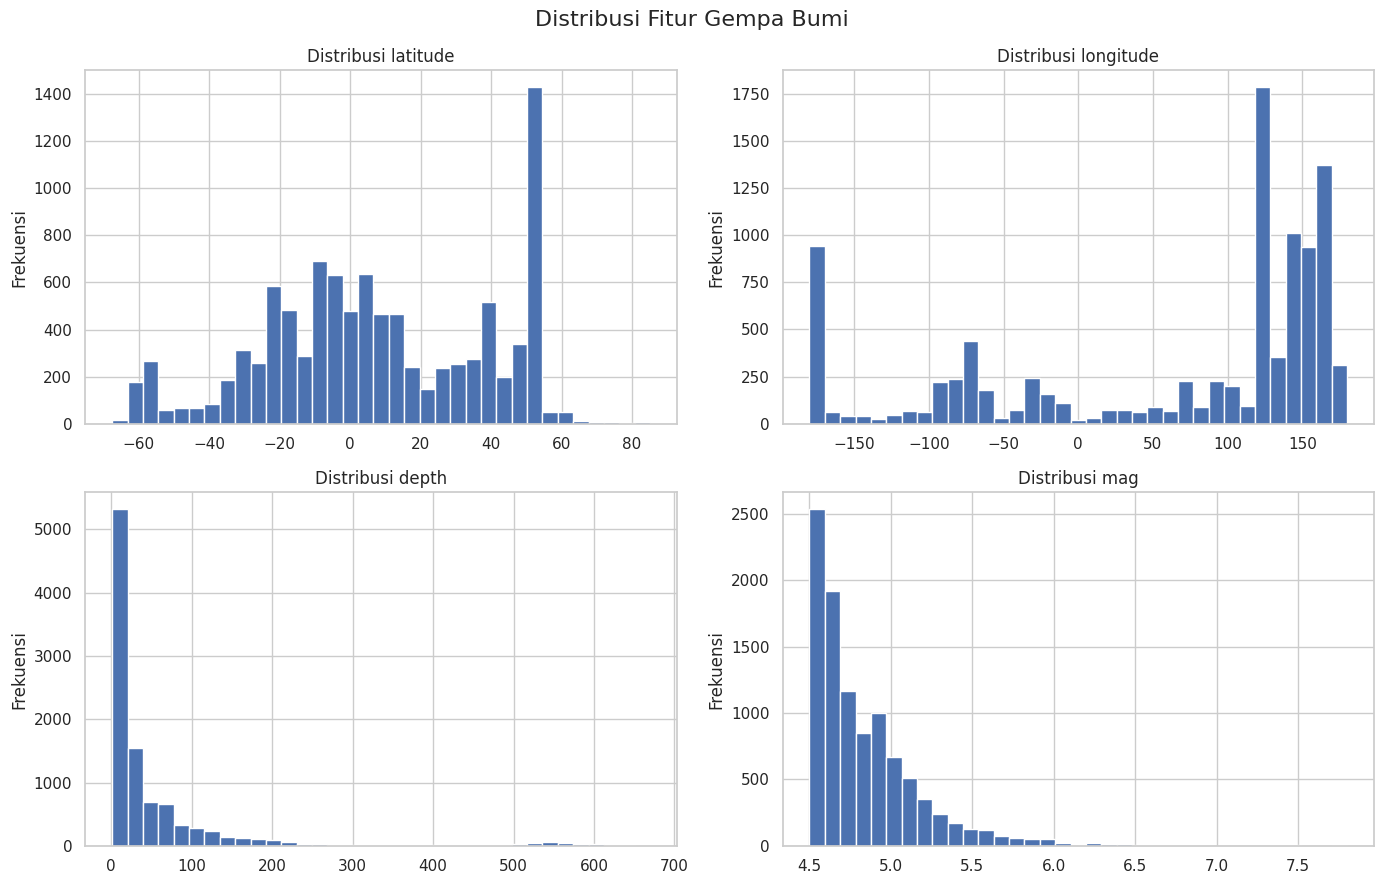

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, feature in zip(axes.flatten(), FEATURES):
    ax.hist(df[feature].dropna(), bins=35, edgecolor="white")
    ax.set_title(f"Distribusi {feature}")
    ax.set_ylabel("Frekuensi")
plt.suptitle("Distribusi Fitur Gempa Bumi", fontsize=16)
plt.tight_layout()
plt.show()


**Interpretasi:** jelaskan fitur dengan sebaran lebar, distribusi menceng, atau konsentrasi pada rentang tertentu. Hindari menyimpulkan penyebab gempa hanya dari histogram.

### 4.2 Boxplot dan nilai ekstrem

Boxplot menandai observasi yang jauh dari rentang mayoritas. Nilai ekstrem tidak otomatis merupakan kesalahan.

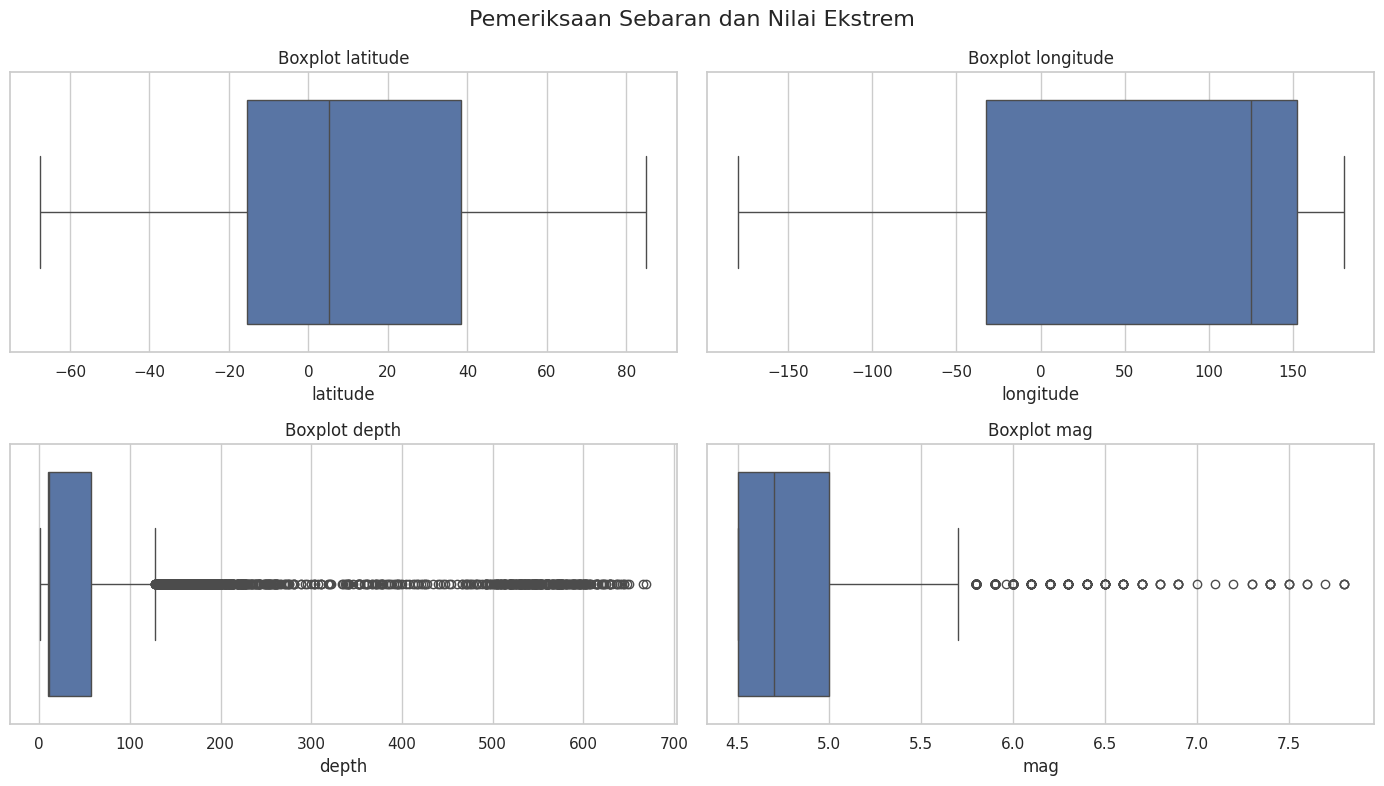

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, feature in zip(axes.flatten(), FEATURES):
    sns.boxplot(x=df[feature], ax=ax)
    ax.set_title(f"Boxplot {feature}")
plt.suptitle("Pemeriksaan Sebaran dan Nilai Ekstrem", fontsize=16)
plt.tight_layout()
plt.show()


### 4.3 Identifikasi outlier dengan aturan IQR

Aturan IQR dipakai sebagai diagnosis. Observasi yang ditandai tetap dipertahankan dalam model utama.

In [7]:
outlier_rows = []
for feature in FEATURES:
    q1, q3 = df[feature].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flagged = ~df[feature].between(lower, upper)
    outlier_rows.append({
        "fitur": feature,
        "batas_bawah_IQR": lower,
        "batas_atas_IQR": upper,
        "jumlah_terindikasi": int(flagged.sum()),
        "persentase": round(flagged.mean() * 100, 2)
    })
outlier_report = pd.DataFrame(outlier_rows)
display(outlier_report)


,fitur,batas_bawah_IQR,batas_atas_IQR,jumlah_terindikasi,persentase
0,latitude,-96.212962,119.134937,0,0.00
1,longitude,-309.662737,429.452963,0,0.00
2,depth,-60.496625,127.494375,994,9.94
3,mag,3.750000,5.750000,280,2.80


### 4.4 Korelasi antarfitur

Heatmap Pearson menunjukkan hubungan linear, bukan sebab-akibat.

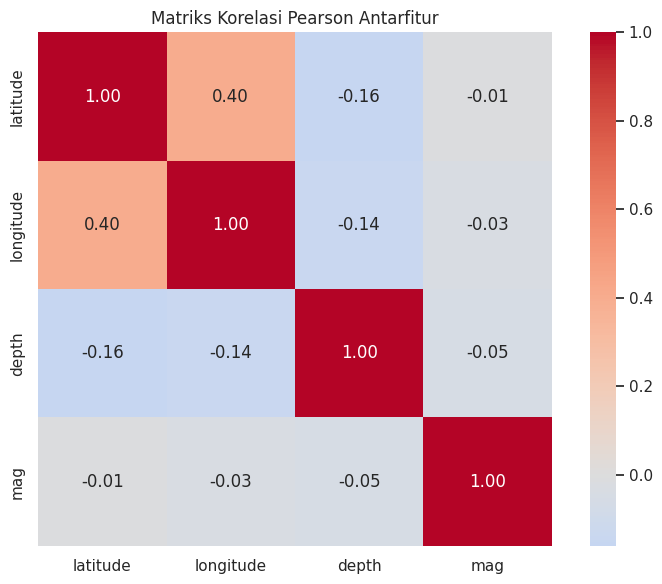

,latitude,longitude,depth,mag
latitude,1.000,0.401,-0.161,-0.013
longitude,0.401,1.000,-0.145,-0.034
depth,-0.161,-0.145,1.000,-0.046
mag,-0.013,-0.034,-0.046,1.000


In [8]:
correlation = df[FEATURES].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", center=0, fmt=".2f", square=True)
plt.title("Matriks Korelasi Pearson Antarfitur")
plt.tight_layout()
plt.show()
display(correlation.round(3))


### 4.5 Hubungan berpasangan antarfitur

Pairplot menggunakan sampel acak maksimal 2.000 baris agar lebih efisien.

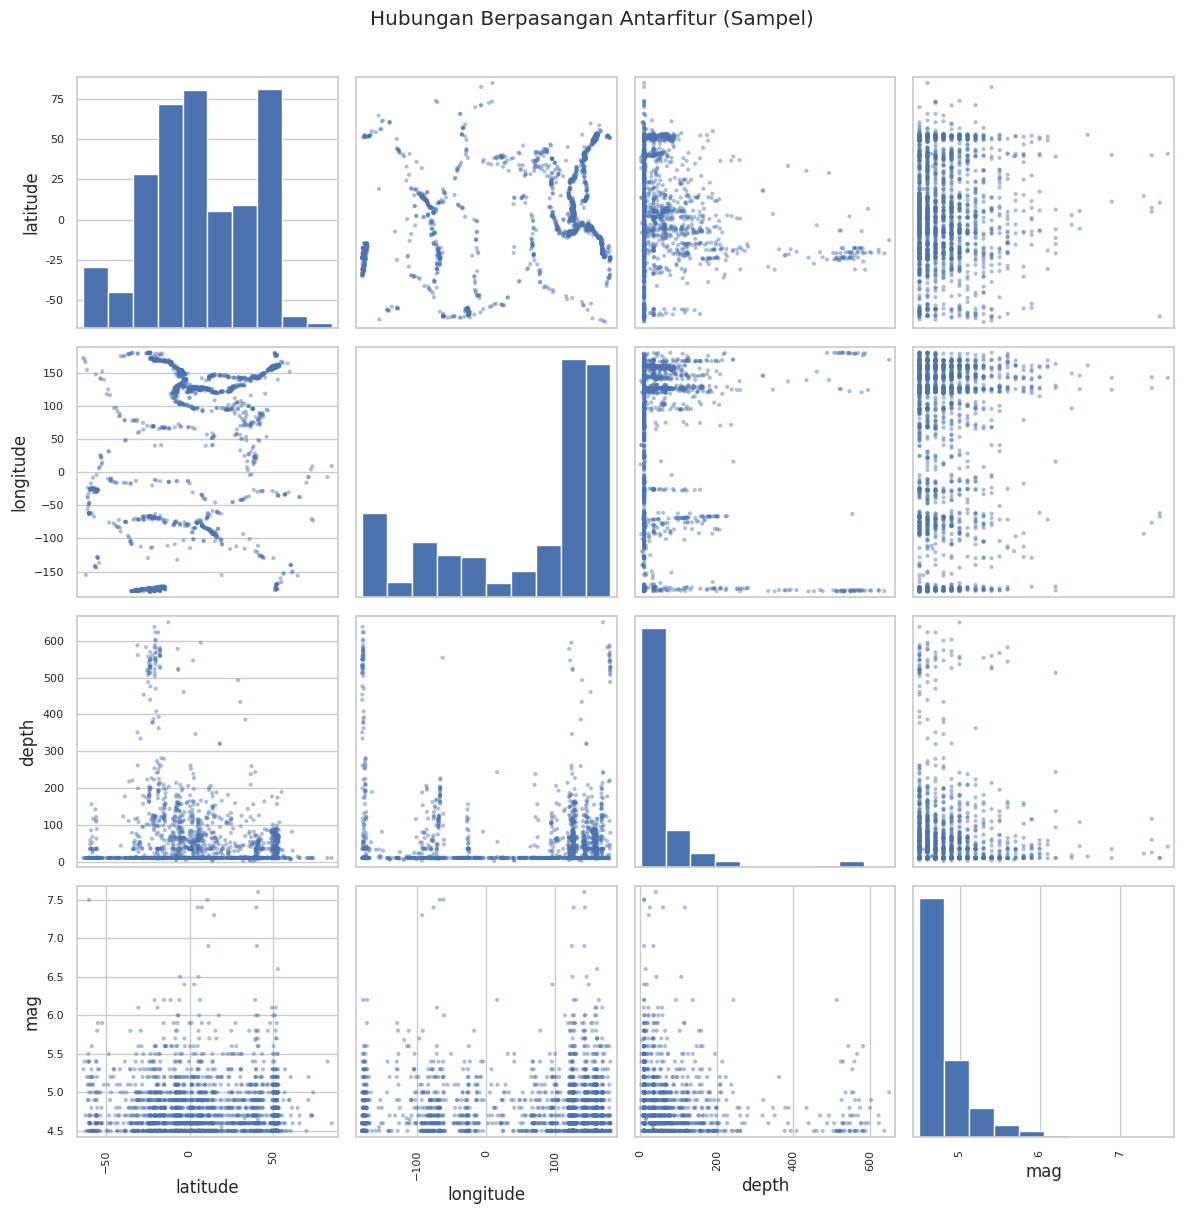

In [9]:
pairplot_data = df[FEATURES].sample(n=min(2000, len(df)), random_state=RANDOM_STATE)
from pandas.plotting import scatter_matrix

scatter_matrix(pairplot_data, figsize=(12, 12), diagonal="hist", alpha=0.45)
plt.suptitle("Hubungan Berpasangan Antarfitur (Sampel)", y=1.01)
plt.tight_layout()
plt.show()

## 5. Pra-pemrosesan: standarisasi

K-Means menggunakan jarak Euclidean. StandardScaler menyetarakan skala fitur agar variabel dengan rentang angka besar tidak mendominasi perhitungan jarak. Nilai ekstrem tetap dipertahankan.

In [10]:
X = df[FEATURES].copy()
scaler = StandardScaler()
X_scaled_array = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled_array, columns=FEATURES, index=df.index)

display(X_scaled.describe().T.round(3))
display(pd.DataFrame({
    "mean_setelah_scaling": X_scaled.mean(),
    "std_populasi_setelah_scaling": X_scaled.std(ddof=0)
}).round(4))


,count,mean,std,min,25%,50%,75%,max
latitude,9998.0,0.0,1.0,-2.360,-0.730,-0.082,0.958,2.421
longitude,9998.0,-0.0,1.0,-2.076,-0.809,0.544,0.778,1.016
depth,9998.0,-0.0,1.0,-0.541,-0.455,-0.445,0.008,6.038
mag,9998.0,0.0,1.0,-0.849,-0.849,-0.305,0.512,8.137


,mean_setelah_scaling,std_populasi_setelah_scaling
latitude,0.0,1.0
longitude,-0.0,1.0
depth,-0.0,1.0
mag,0.0,1.0


## 6. Menentukan jumlah cluster

K diuji dari 2 sampai 8. Elbow Method mengamati inertia; Silhouette Score menilai kesesuaian anggota dengan cluster sendiri dibandingkan cluster lain. Silhouette dihitung dari sampel acak konsisten untuk mengendalikan waktu komputasi.

In [11]:
inertia_values = []
silhouette_values = []

for k in K_VALUES:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = model.fit_predict(X_scaled)
    inertia_values.append(model.inertia_)
    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=min(SILHOUETTE_SAMPLE_SIZE, len(X_scaled)),
        random_state=RANDOM_STATE
    )
    silhouette_values.append(score)

evaluation_df = pd.DataFrame({
    "K": K_VALUES,
    "Inertia": inertia_values,
    "Silhouette_Score_Sampel": silhouette_values
})
display(evaluation_df.round(4))


,K,Inertia,Silhouette_Score_Sampel
0,2,29092.3881,0.3609
1,3,22097.9645,0.3772
2,4,17372.4385,0.3868
3,5,13841.8343,0.3423
4,6,12187.5296,0.3489
5,7,11117.4943,0.3330
6,8,10205.9278,0.3263


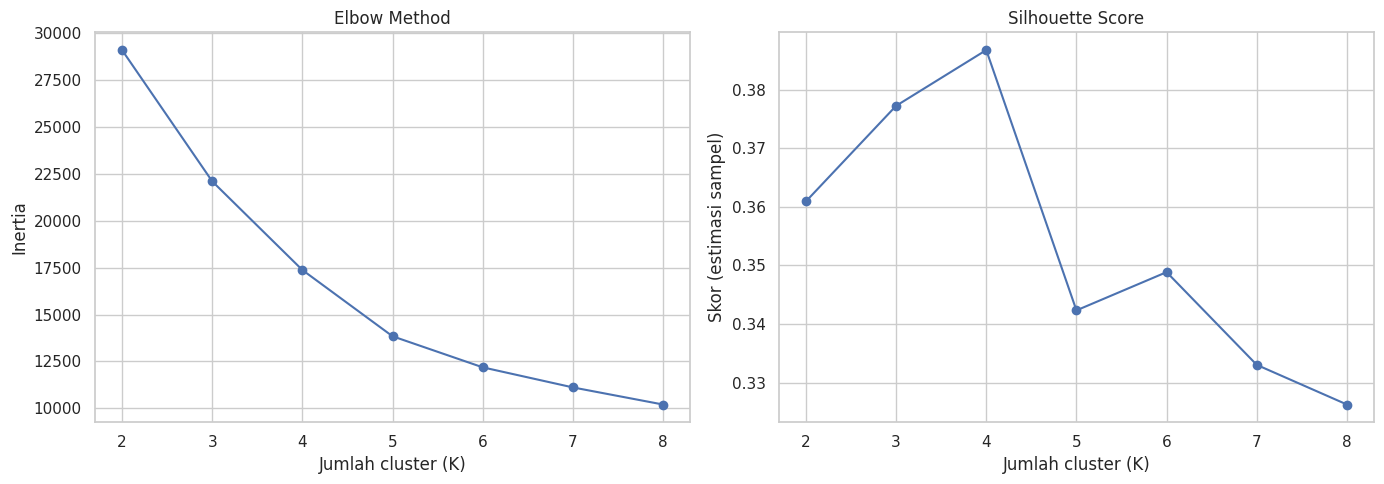

K dengan Silhouette Score sampel tertinggi: 4


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(evaluation_df["K"], evaluation_df["Inertia"], marker="o")
axes[0].set(title="Elbow Method", xlabel="Jumlah cluster (K)", ylabel="Inertia")
axes[0].set_xticks(K_VALUES)

axes[1].plot(evaluation_df["K"], evaluation_df["Silhouette_Score_Sampel"], marker="o")
axes[1].set(title="Silhouette Score", xlabel="Jumlah cluster (K)", ylabel="Skor (estimasi sampel)")
axes[1].set_xticks(K_VALUES)

plt.tight_layout()
plt.show()

best_k = int(evaluation_df.loc[evaluation_df["Silhouette_Score_Sampel"].idxmax(), "K"])
print("K dengan Silhouette Score sampel tertinggi:", best_k)


**Keputusan K:** jangan memilih K hanya karena inertia paling kecil. Pertimbangkan titik siku, Silhouette Score, ukuran cluster, dan kemudahan interpretasi. K dengan skor tertinggi adalah kandidat, bukan keputusan otomatis.

## 7. Pemodelan K-Means

Nilai awal K=4 dipertahankan sebagai pembanding hasil sebelumnya. Tinjau grafik evaluasi dan ubah `SELECTED_K` jika analisis mendukung pilihan lain.

In [13]:
if SELECTED_K not in K_VALUES:
    raise ValueError(f"SELECTED_K harus berada pada rentang {K_VALUES}")

kmeans = KMeans(n_clusters=SELECTED_K, random_state=RANDOM_STATE, n_init=20)
cluster_labels = kmeans.fit_predict(X_scaled)

df_clustered = df.copy()
df_clustered["cluster"] = cluster_labels

final_inertia = kmeans.inertia_
final_silhouette_sample = silhouette_score(
    X_scaled,
    cluster_labels,
    sample_size=min(SILHOUETTE_SAMPLE_SIZE, len(X_scaled)),
    random_state=RANDOM_STATE
)

print("Jumlah cluster:", SELECTED_K)
print(f"Inertia: {final_inertia:.3f}")
print(f"Silhouette Score (estimasi sampel): {final_silhouette_sample:.4f}")

cluster_counts = df_clustered["cluster"].value_counts().sort_index().to_frame("jumlah_data")
cluster_counts["persentase"] = (cluster_counts["jumlah_data"] / len(df_clustered) * 100).round(2)
display(cluster_counts)


Jumlah cluster: 4
Inertia: 17372.439
Silhouette Score (estimasi sampel): 0.3868


,jumlah_data,persentase
cluster,,
0,5980,59.81
1,2625,26.26
2,354,3.54
3,1039,10.39


## 8. Evaluasi silhouette per cluster

Silhouette per observasi membantu melihat apakah ada kelompok yang banyak memiliki anggota dengan skor rendah atau negatif. Plot dibuat dari sampel.

In [14]:
sample_n = min(SILHOUETTE_SAMPLE_SIZE, len(X_scaled))
rng = np.random.RandomState(RANDOM_STATE)
sample_positions = rng.choice(len(X_scaled), size=sample_n, replace=False)

X_sil_sample = X_scaled.iloc[sample_positions]
labels_sil_sample = cluster_labels[sample_positions]
silhouette_vals = silhouette_samples(X_sil_sample, labels_sil_sample)

silhouette_by_cluster = pd.DataFrame({
    "cluster": labels_sil_sample,
    "silhouette": silhouette_vals
}).groupby("cluster")["silhouette"].agg(
    jumlah="count", rata_rata="mean", median="median",
    minimum="min", maksimum="max"
)
display(silhouette_by_cluster.round(4))


,jumlah,rata_rata,median,minimum,maksimum
cluster,,,,,
0,1787,0.4531,0.4851,0.0535,0.6119
1,777,0.3045,0.3147,-0.1187,0.5216
2,117,0.5056,0.5442,-0.1224,0.6481
3,319,0.1721,0.1702,-0.1271,0.4495


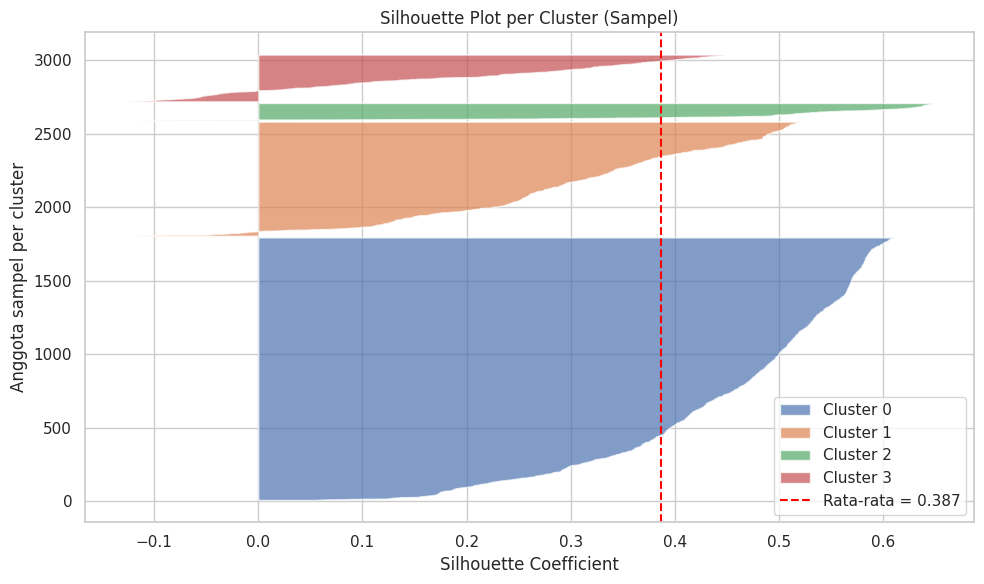

In [15]:
plt.figure(figsize=(10, 6))
y_lower = 10
for cluster_id in sorted(np.unique(labels_sil_sample)):
    values = np.sort(silhouette_vals[labels_sil_sample == cluster_id])
    y_upper = y_lower + len(values)
    plt.fill_betweenx(np.arange(y_lower, y_upper), 0, values, alpha=0.7,
                      label=f"Cluster {cluster_id}")
    y_lower = y_upper + 10

plt.axvline(final_silhouette_sample, color="red", linestyle="--",
            label=f"Rata-rata = {final_silhouette_sample:.3f}")
plt.title("Silhouette Plot per Cluster (Sampel)")
plt.xlabel("Silhouette Coefficient")
plt.ylabel("Anggota sampel per cluster")
plt.legend()
plt.tight_layout()
plt.show()


## 9. Profil dan interpretasi karakteristik cluster

Profil dihitung dalam satuan asli menggunakan mean, median, minimum, dan maksimum. Median penting karena distribusi kedalaman dan magnitudo dapat menceng.

In [16]:
cluster_profile = df_clustered.groupby("cluster")[FEATURES].agg(
    ["count", "mean", "median", "min", "max"]
)
display(cluster_profile.round(3))

cluster_summary = df_clustered.groupby("cluster")[FEATURES].agg(["mean", "median"])
cluster_summary.columns = [f"{feature}_{stat}" for feature, stat in cluster_summary.columns]
cluster_summary.insert(0, "jumlah_data", df_clustered.groupby("cluster").size())
cluster_summary["persentase"] = (cluster_summary["jumlah_data"] / len(df_clustered) * 100).round(2)
display(cluster_summary.round(3))


latitude                                  ...   mag                        
           count    mean  median     min     max  ... count   mean median  min  max
cluster                                           ...                              
0           5980  19.903  16.490 -63.902  85.064  ...  5980  4.702    4.6  4.5  5.2
1           2625 -17.711 -22.299 -67.469  64.743  ...  2625  4.760    4.7  4.5  5.6
2            354 -14.601 -20.478 -31.824  51.508  ...   354  4.746    4.6  4.5  7.1
3           1039  10.430   7.213 -65.000  82.587  ...  1039  5.601    5.5  5.1  7.8

[4 rows x 20 columns]

,jumlah_data,latitude_mean,latitude_median,longitude_mean,longitude_median,depth_mean,depth_median,mag_mean,mag_median,persentase
cluster,,,,,,,,,,
0,5980,19.903,16.490,131.215,140.902,38.409,14.357,4.702,4.6,59.81
1,2625,-17.711,-22.299,-91.248,-81.472,42.093,10.000,4.760,4.7,26.26
2,354,-14.601,-20.478,-27.513,-177.474,518.619,537.282,4.746,4.6,3.54
3,1039,10.430,7.213,78.103,125.430,36.466,14.000,5.601,5.5,10.39


### 9.1 Rata-rata fitur pada skala asli

Grafik ini menunjukkan rata-rata fitur per cluster. Karena satuan fitur berbeda, tinggi batang antarfitur tidak dibandingkan langsung.

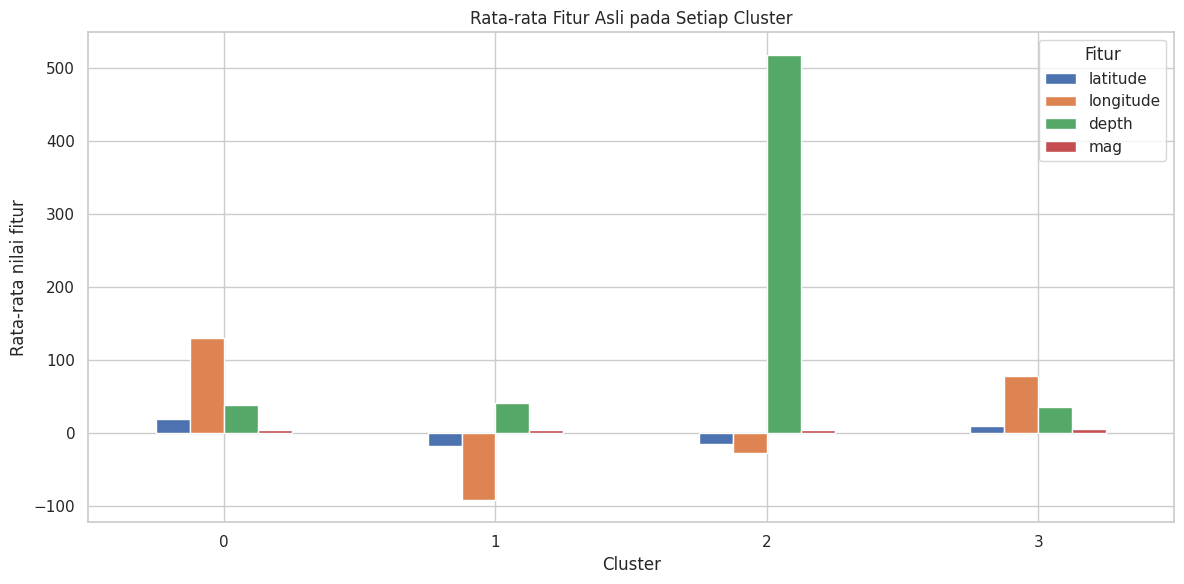

In [17]:
cluster_means = df_clustered.groupby("cluster")[FEATURES].mean()
cluster_means.plot(kind="bar", figsize=(12, 6))
plt.title("Rata-rata Fitur Asli pada Setiap Cluster")
plt.xlabel("Cluster")
plt.ylabel("Rata-rata nilai fitur")
plt.xticks(rotation=0)
plt.legend(title="Fitur")
plt.tight_layout()
plt.show()


### 9.2 Profil fitur pada skala terstandarisasi

Heatmap ini lebih sesuai untuk membandingkan pola relatif antarfitur karena skala fitur telah disetarakan.

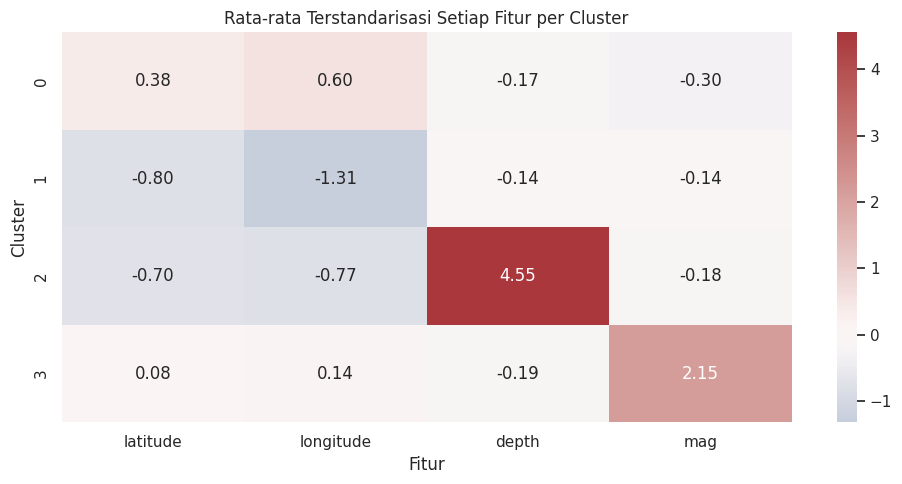

In [18]:
scaled_with_cluster = X_scaled.copy()
scaled_with_cluster["cluster"] = cluster_labels
scaled_cluster_means = scaled_with_cluster.groupby("cluster")[FEATURES].mean()

plt.figure(figsize=(10, 5))
sns.heatmap(scaled_cluster_means, annot=True, cmap="vlag", center=0, fmt=".2f")
plt.title("Rata-rata Terstandarisasi Setiap Fitur per Cluster")
plt.xlabel("Fitur")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()


## 10. Visualisasi cluster dengan PCA

PCA mereduksi empat fitur menjadi dua komponen untuk visualisasi. Label cluster tetap berasal dari K-Means yang dilatih menggunakan empat fitur terstandarisasi.

Variansi PC1: 37.39%
Variansi PC2: 25.66%
Total variansi PC1 + PC2: 63.05%


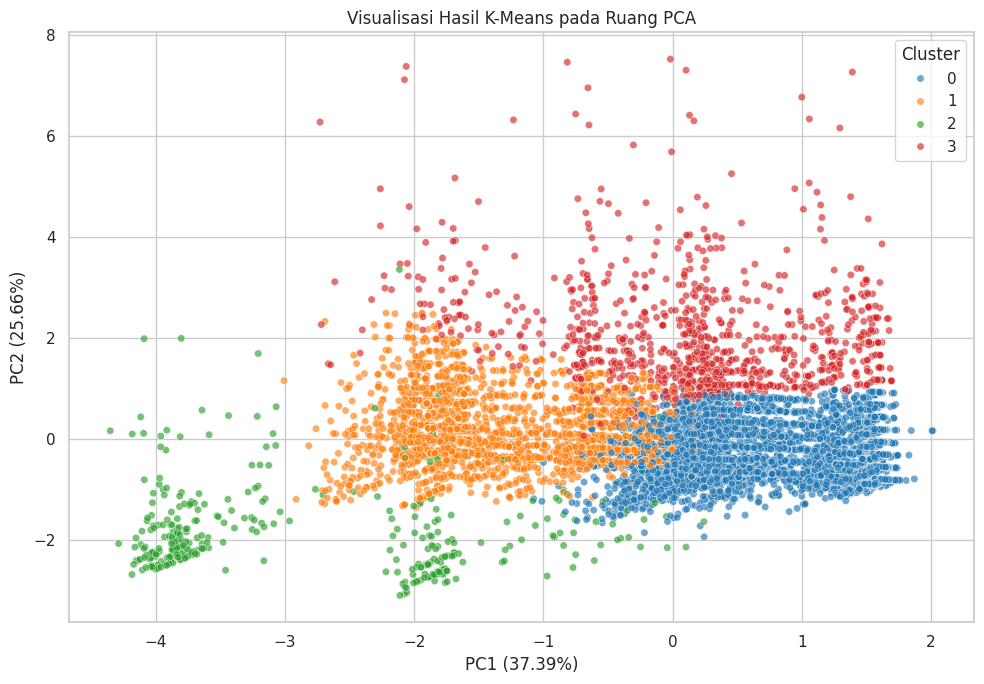

In [19]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"], index=df.index)
pca_df["cluster"] = cluster_labels

pc1_pct = pca.explained_variance_ratio_[0] * 100
pc2_pct = pca.explained_variance_ratio_[1] * 100
total_pct = pca.explained_variance_ratio_.sum() * 100

print(f"Variansi PC1: {pc1_pct:.2f}%")
print(f"Variansi PC2: {pc2_pct:.2f}%")
print(f"Total variansi PC1 + PC2: {total_pct:.2f}%")

plt.figure(figsize=(10, 7))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="cluster",
                palette="tab10", alpha=0.65, s=28)
plt.title("Visualisasi Hasil K-Means pada Ruang PCA")
plt.xlabel(f"PC1 ({pc1_pct:.2f}%)")
plt.ylabel(f"PC2 ({pc2_pct:.2f}%)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()


**Interpretasi PCA:** jelaskan apakah cluster terlihat terpisah, saling tumpang tindih, atau menyebar. Dua komponen PCA hanya menjelaskan sebagian variasi data sehingga bukan representasi sempurna dari ruang empat dimensi.

## 11. Visualisasi sebaran geografis

Grafik koordinat memperlihatkan posisi lintang dan bujur berdasarkan label cluster. Ini bukan peta proyeksi dan tidak menggunakan jarak geodesik.

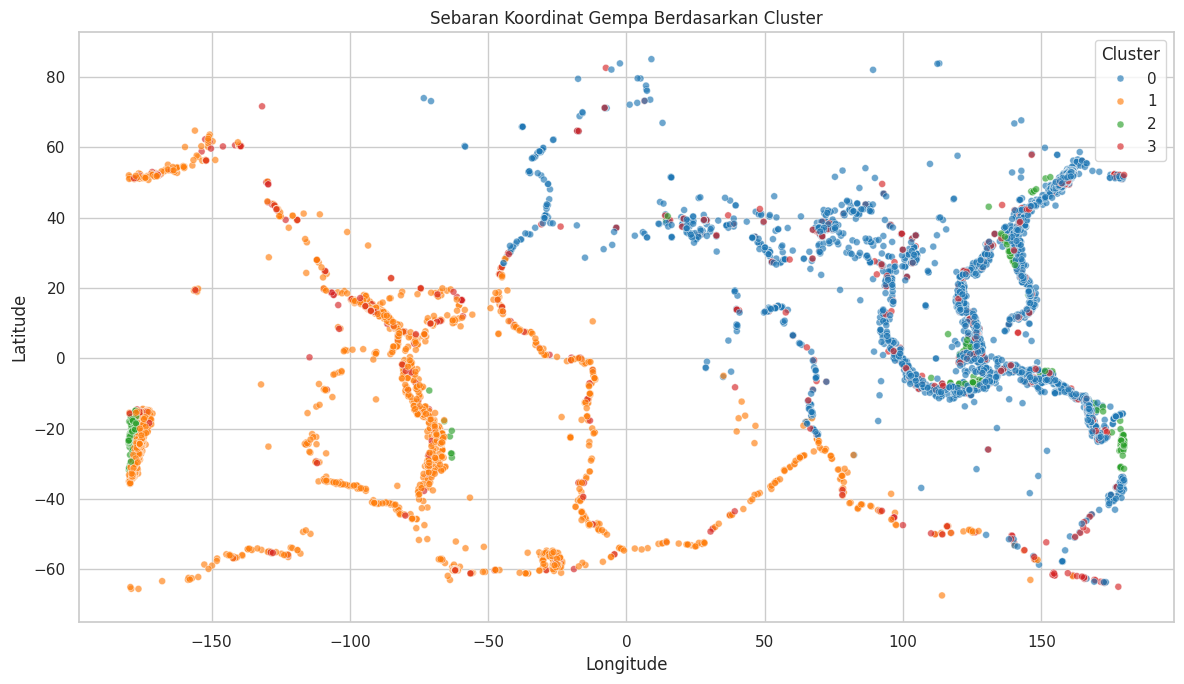

In [20]:
plt.figure(figsize=(12, 7))
sns.scatterplot(data=df_clustered, x="longitude", y="latitude",
                hue="cluster", palette="tab10", alpha=0.65, s=25)
plt.title("Sebaran Koordinat Gempa Berdasarkan Cluster")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()


## 12. Centroid cluster dalam satuan asli

Centroid K-Means terbentuk pada skala terstandarisasi. Nilainya dikembalikan ke satuan asli untuk membantu interpretasi. Centroid merupakan pusat matematis, bukan selalu lokasi kejadian gempa yang benar-benar ada.

In [21]:
centroids_original = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),
    columns=FEATURES
)
centroids_original.index.name = "cluster"
display(centroids_original.round(3))


,latitude,longitude,depth,mag
cluster,,,,
0,19.897,131.205,38.404,4.702
1,-17.703,-91.318,42.175,4.760
2,-14.601,-27.513,518.619,4.746
3,10.463,78.453,36.276,5.601


## 13. Ekspor hasil analisis

File yang dihasilkan: data normalisasi dengan label cluster, data hasil clustering, ringkasan cluster, evaluasi K, dan centroid dalam satuan asli.

In [22]:
X_scaled_export = X_scaled.copy()
X_scaled_export["cluster"] = cluster_labels
X_scaled_export.to_csv(OUTPUT_DIR / "data_normalisasi.csv", index=False)

df_clustered.to_csv(OUTPUT_DIR / "data_hasil_clustering.csv", index=False)
cluster_summary.to_csv(OUTPUT_DIR / "ringkasan_cluster.csv")
evaluation_df.to_csv(OUTPUT_DIR / "evaluasi_jumlah_cluster.csv", index=False)
centroids_original.to_csv(OUTPUT_DIR / "centroid_cluster.csv")

print("File hasil disimpan di:", OUTPUT_DIR.resolve())
for file in sorted(OUTPUT_DIR.glob("*.csv")):
    print("-", file.name)


File hasil disimpan di: /mnt/data/output_clustering_revisi
- centroid_cluster.csv
- data_hasil_clustering.csv
- data_normalisasi.csv
- evaluasi_jumlah_cluster.csv
- ringkasan_cluster.csv


## 14. Kesimpulan dan bahan penulisan laporan

Lengkapi bagian ini setelah seluruh sel dijalankan. Gunakan angka aktual dari output notebook.

### Poin yang harus dijawab
1. Berapa jumlah data awal dan jumlah data setelah filter serta pembersihan?
2. Bagaimana distribusi latitude, longitude, depth, dan magnitude?
3. Apakah terdapat nilai ekstrem? Bagaimana keputusan penanganannya?
4. Mengapa StandardScaler digunakan?
5. Bagaimana pola Elbow Method dan Silhouette Score? Mengapa K dipilih?
6. Berapa anggota setiap cluster?
7. Apa karakteristik setiap cluster berdasarkan mean dan median?
8. Apakah cluster terlihat terpisah pada silhouette plot dan PCA?
9. Apa keterbatasan K-Means pada data gempa bumi dengan koordinat geografis?

### Batasan analisis
- K-Means sensitif terhadap skala fitur, outlier, pemilihan fitur, dan jumlah cluster.
- Latitude dan longitude pada model ini tidak menggunakan jarak geodesik.
- PCA dua dimensi hanya menampilkan sebagian informasi dari empat fitur.
- Cluster adalah pola statistik dalam dataset, bukan klasifikasi resmi tingkat bahaya gempa.

**Kesimpulan akhir:** rangkum hasil, alasan pemilihan K, karakteristik cluster, kualitas pemisahan, dan keterbatasan metode. Jangan menyatakan model sangat baik hanya berdasarkan satu nilai metrik.
